# Member 4 – XGBoost Model and Final Evaluation

## Project
Predictive Maintenance of Scania Truck Air Pressure Systems Using Supervised Machine Learning

## Objectives
1. Train an XGBoost classifier.
2. Use the shared preprocessing pipeline.
3. Perform 5-fold stratified cross-validation.
4. Evaluate Precision, Recall, F1-score, ROC-AUC and Average Precision.
5. Compare all six machine learning models.

## Dataset
- Training records: 60,000
- Features: 170
- Non-APS: 59,000
- APS Failure: 1,000

In [18]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from src.preprocessing import (
    load_aps_csv,
    split_development_data,
    make_training_pipeline
)

RANDOM_STATE = 42

print("All imports completed successfully!")

All imports completed successfully!


In [19]:
# Add project root to Python path

import sys
from pathlib import Path

current = Path.cwd()

project_root = next(
    (p for p in [current, *current.parents]
     if (p / "src" / "preprocessing.py").exists()),
    None
)

if project_root is None:
    raise FileNotFoundError("Could not locate src/preprocessing.py")

sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("Source folder found:", (project_root / "src").exists())

Project root: d:\Semester 05\EC5203 Machine Learning\ML Project\scania-predictive-maintenance-git
Source folder found: True


## 1. Dataset Loading and Preparation

Load the Scania APS training dataset using the shared preprocessing module.

Split the original training data into:
- Development set (80%)
- Internal holdout set (20%)

The official test dataset will remain untouched until final evaluation.

In [20]:
# Load the Scania APS dataset

DATA_PATH = "../data/aps_failure_training_set.csv"

X, y = load_aps_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Original feature shape:", X.shape)
print("Original target shape:", y.shape)

print("\nOriginal class distribution:")
print(y.value_counts())

print("\nMissing values in dataset:", X.isna().sum().sum())

Dataset loaded successfully!
Original feature shape: (60000, 170)
Original target shape: (60000,)

Original class distribution:
class
0    59000
1     1000
Name: count, dtype: int64

Missing values in dataset: 850015


In [21]:
# Split dataset into development and internal holdout sets

X_dev, X_holdout, y_dev, y_holdout = split_development_data(X, y)

print("Development set:", X_dev.shape)
print("Internal holdout set:", X_holdout.shape)

print("\nDevelopment class distribution:")
print(y_dev.value_counts())

print("\nHoldout class distribution:")
print(y_holdout.value_counts())

Development set: (48000, 170)
Internal holdout set: (12000, 170)

Development class distribution:
class
0    47200
1      800
Name: count, dtype: int64

Holdout class distribution:
class
0    11800
1      200
Name: count, dtype: int64


## 2. XGBoost Model – Five-Fold Cross-Validation

Train and evaluate XGBoost using five-fold stratified cross-validation.

Each fold will:
- Fit preprocessing only on its training portion.
- Calculate scale_pos_weight from its training labels.
- Train a fresh XGBoost model.
- Predict probabilities for its validation portion.

The internal holdout and official test set will remain untouched.

In [22]:
# Import additional evaluation tools

from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

from sklearn.model_selection import StratifiedKFold

# Initial XGBoost configuration

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("XGBoost model configured successfully!")

XGBoost model configured successfully!


In [23]:
# Configure 5-fold stratified cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation configured!")
print("Number of folds:", cv.get_n_splits())

Cross-validation configured!
Number of folds: 5


In [24]:
# Store fold-level evaluation results

fold_results = []

print("Ready for XGBoost cross-validation!")

Ready for XGBoost cross-validation!


In [25]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("XGBoost model configured successfully!")

XGBoost model configured successfully!


In [26]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation configured!")
print("Number of folds:", cv.get_n_splits())

Cross-validation configured!
Number of folds: 5


In [27]:
# XGBoost: 5-Fold Stratified Cross-Validation

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_dev, y_dev), start=1
):

    print(f"\n========== Fold {fold} ==========")

    # Split development data
    X_train_fold = X_dev.iloc[train_idx]
    X_val_fold = X_dev.iloc[val_idx]

    y_train_fold = y_dev.iloc[train_idx]
    y_val_fold = y_dev.iloc[val_idx]

    # Calculate class weight using training fold only
    negative_count = (y_train_fold == 0).sum()
    positive_count = (y_train_fold == 1).sum()

    scale_pos_weight = negative_count / positive_count

    print("Training records:", len(X_train_fold))
    print("Validation records:", len(X_val_fold))
    print("Negative samples:", negative_count)
    print("Positive samples:", positive_count)
    print("Scale pos weight:", round(scale_pos_weight, 2))

    # Create a fresh model for this fold
    fold_model = clone(xgb_model)
    fold_model.set_params(scale_pos_weight=scale_pos_weight)

    # Build preprocessing and model pipeline
    pipeline = make_training_pipeline(
        fold_model,
        scale=False,
        add_indicators=False,
        use_smote=False
    )

    # Train the model
    pipeline.fit(X_train_fold, y_train_fold)

    # Predict validation probabilities
    y_prob = pipeline.predict_proba(X_val_fold)[:, 1]

    # Apply default threshold
    y_pred = (y_prob >= 0.5).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(
        y_val_fold, y_pred, zero_division=0
    )

    recall = recall_score(y_val_fold, y_pred)

    f1 = f1_score(
        y_val_fold, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y_val_fold, y_prob)

    avg_precision = average_precision_score(
        y_val_fold, y_prob
    )

    # Store fold results
    fold_results.append({
        "Fold": fold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "Average Precision": avg_precision,
        "Scale Pos Weight": scale_pos_weight
    })

    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"Average Precision: {avg_precision:.4f}")

print("\nAll five folds completed!")


========== Fold 1 ==========
Training records: 38400
Validation records: 9600
Negative samples: 37760
Positive samples: 640
Scale pos weight: 59.0
Precision: 0.7816
Recall: 0.8500
F1-score: 0.8144
ROC-AUC: 0.9849
Average Precision: 0.8858

========== Fold 2 ==========
Training records: 38400
Validation records: 9600
Negative samples: 37760
Positive samples: 640
Scale pos weight: 59.0
Precision: 0.7427
Recall: 0.7937
F1-score: 0.7674
ROC-AUC: 0.9909
Average Precision: 0.8602

========== Fold 3 ==========
Training records: 38400
Validation records: 9600
Negative samples: 37760
Positive samples: 640
Scale pos weight: 59.0
Precision: 0.7403
Recall: 0.8375
F1-score: 0.7859
ROC-AUC: 0.9936
Average Precision: 0.8864

========== Fold 4 ==========
Training records: 38400
Validation records: 9600
Negative samples: 37760
Positive samples: 640
Scale pos weight: 59.0
Precision: 0.7733
Recall: 0.8313
F1-score: 0.8012
ROC-AUC: 0.9837
Average Precision: 0.8897

========== Fold 5 ==========
Training r

## 3. Cross-Validation Results

Summarize the five-fold XGBoost performance using mean and standard deviation for each evaluation metric.

In [28]:
# Convert fold results into a DataFrame

xgb_results_df = pd.DataFrame(fold_results)

display(xgb_results_df.round(4))

# Calculate mean and standard deviation

metrics_summary = xgb_results_df[
    ["Precision", "Recall", "F1", "ROC-AUC", "Average Precision"]
].agg(["mean", "std"])

print("\nXGBoost Cross-Validation Summary:")
display(metrics_summary.round(4))

,Fold,Precision,Recall,F1,ROC-AUC,Average Precision,Scale Pos Weight
0,1,0.7816,0.8500,0.8144,0.9849,0.8858,59.0
1,2,0.7427,0.7938,0.7674,0.9909,0.8602,59.0
2,3,0.7403,0.8375,0.7859,0.9936,0.8864,59.0
3,4,0.7733,0.8312,0.8012,0.9837,0.8897,59.0
4,5,0.7308,0.8312,0.7778,0.9903,0.8761,59.0



XGBoost Cross-Validation Summary:


,Precision,Recall,F1,ROC-AUC,Average Precision
mean,0.7537,0.8288,0.7893,0.9887,0.8796
std,0.0223,0.0210,0.0187,0.0042,0.0120


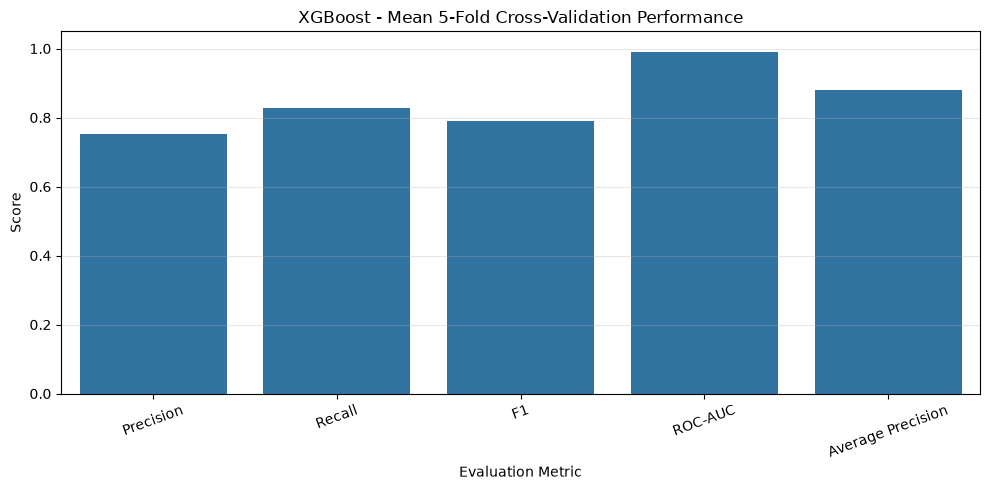

In [29]:
# Visualize mean cross-validation metrics

mean_metrics = xgb_results_df[
    ["Precision", "Recall", "F1", "ROC-AUC", "Average Precision"]
].mean()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=mean_metrics.index,
    y=mean_metrics.values
)

plt.title("XGBoost - Mean 5-Fold Cross-Validation Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
# Create results directory and save fold-level metrics

from pathlib import Path

results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)

xgb_results_df.to_csv(
    results_dir / "xgboost_cv_results.csv",
    index=False
)

metrics_summary.to_csv(
    results_dir / "xgboost_cv_summary.csv"
)

print("XGBoost results saved successfully!")

XGBoost results saved successfully!


In [31]:

from sklearn.base import clone
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

# Store predictions for every development-data row
oof_predictions = np.zeros(len(y_dev), dtype=int)
oof_probabilities = np.zeros(len(y_dev), dtype=float)

# Repeat the 5-fold process and collect validation predictions
for fold, (train_idx, val_idx) in enumerate(cv.split(X_dev, y_dev), start=1):

    X_train_fold = X_dev.iloc[train_idx]
    X_val_fold = X_dev.iloc[val_idx]

    y_train_fold = y_dev.iloc[train_idx]
    y_val_fold = y_dev.iloc[val_idx]

    # Calculate class weight using only the training fold
    negative_count = (y_train_fold == 0).sum()
    positive_count = (y_train_fold == 1).sum()
    scale_pos_weight = negative_count / positive_count

    # Create and configure a fresh model
    fold_model = clone(xgb_model)
    fold_model.set_params(scale_pos_weight=scale_pos_weight)

    pipeline = make_training_pipeline(
        fold_model,
        scale=False,
        add_indicators=False,
        use_smote=False
    )

    pipeline.fit(X_train_fold, y_train_fold)

    # Predict validation-fold probabilities and classes
    probabilities = pipeline.predict_proba(X_val_fold)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    # Save predictions in their original row positions
    oof_probabilities[val_idx] = probabilities
    oof_predictions[val_idx] = predictions

print("OOF predictions completed!")
print("Total predictions:", len(oof_predictions))


OOF predictions completed!
Total predictions: 48000


OOF Confusion Matrix:
[[46983   217]
 [  137   663]]


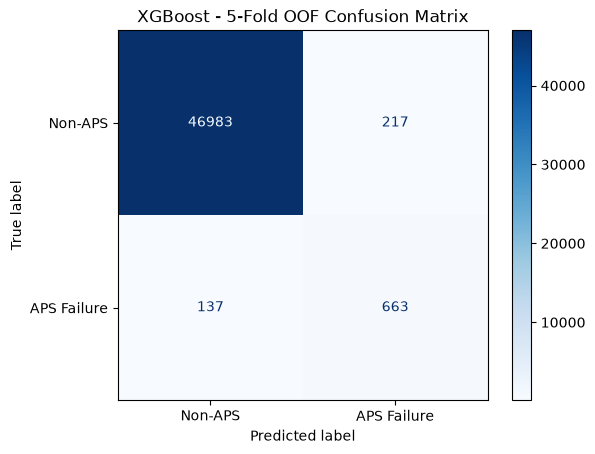

In [32]:

cm = confusion_matrix(y_dev, oof_predictions)

print("OOF Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-APS", "APS Failure"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("XGBoost - 5-Fold OOF Confusion Matrix")
plt.show()


In [33]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

print("OOF Evaluation Results")
print("----------------------")

print("Precision:", precision_score(y_dev, oof_predictions))
print("Recall:", recall_score(y_dev, oof_predictions))
print("F1-score:", f1_score(y_dev, oof_predictions))
print("ROC-AUC:", roc_auc_score(y_dev, oof_probabilities))
print("Average Precision:", average_precision_score(y_dev, oof_probabilities))

print("\nClassification Report:")
print(classification_report(
    y_dev,
    oof_predictions,
    target_names=["Non-APS", "APS Failure"]
))


OOF Evaluation Results
----------------------
Precision: 0.7534090909090909
Recall: 0.82875
F1-score: 0.7892857142857143
ROC-AUC: 0.9884396583686441
Average Precision: 0.8782780545056528

Classification Report:
              precision    recall  f1-score   support

     Non-APS       1.00      1.00      1.00     47200
 APS Failure       0.75      0.83      0.79       800

    accuracy                           0.99     48000
   macro avg       0.88      0.91      0.89     48000
weighted avg       0.99      0.99      0.99     48000



In [34]:

from sklearn.base import clone

# Four configurations to compare
parameter_configs = {
    "Baseline": {
        "n_estimators": 300,
        "max_depth": 6,
        "learning_rate": 0.05
    },
    "Shallow Trees": {
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.05
    },
    "More Trees": {
        "n_estimators": 500,
        "max_depth": 4,
        "learning_rate": 0.05
    },
    "Higher Learning Rate": {
        "n_estimators": 300,
        "max_depth": 6,
        "learning_rate": 0.1
    }
}

tuning_results = []

for config_name, params in parameter_configs.items():

    print(f"Evaluating: {config_name}")

    fold_ap = []
    fold_f1 = []
    fold_recall = []

    for train_idx, val_idx in cv.split(X_dev, y_dev):

        X_train_fold = X_dev.iloc[train_idx]
        X_val_fold = X_dev.iloc[val_idx]

        y_train_fold = y_dev.iloc[train_idx]
        y_val_fold = y_dev.iloc[val_idx]

        # Calculate class weight from training fold
        negative_count = (y_train_fold == 0).sum()
        positive_count = (y_train_fold == 1).sum()

        weight = negative_count / positive_count

        model = clone(xgb_model)
        model.set_params(**params, scale_pos_weight=weight)

        pipeline = make_training_pipeline(
            model,
            scale=False,
            add_indicators=False,
            use_smote=False
        )

        pipeline.fit(X_train_fold, y_train_fold)

        probabilities = pipeline.predict_proba(X_val_fold)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        fold_ap.append(
            average_precision_score(y_val_fold, probabilities)
        )
        fold_f1.append(
            f1_score(y_val_fold, predictions, zero_division=0)
        )
        fold_recall.append(
            recall_score(y_val_fold, predictions)
        )

    tuning_results.append({
        "Configuration": config_name,
        "Mean Average Precision": np.mean(fold_ap),
        "Mean F1": np.mean(fold_f1),
        "Mean Recall": np.mean(fold_recall)
    })

tuning_df = pd.DataFrame(tuning_results)

print("\nHyperparameter Tuning Results:")
display(tuning_df.sort_values(
    by="Mean Average Precision",
    ascending=False
).reset_index(drop=True))


Evaluating: Baseline
Evaluating: Shallow Trees
Evaluating: More Trees
Evaluating: Higher Learning Rate

Hyperparameter Tuning Results:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [35]:

# Display the completed tuning results
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="Mean Average Precision",
    ascending=False
).reset_index(drop=True)

tuning_df


,Configuration,Mean Average Precision,Mean F1,Mean Recall
0,Higher Learning Rate,0.885372,0.813451,0.81250
1,Baseline,0.879620,0.789330,0.82875
2,More Trees,0.875305,0.763127,0.84625
3,Shallow Trees,0.862237,0.699221,0.89500


In [36]:

# Select the leading configuration
best_xgb_model = clone(xgb_model)

best_xgb_model.set_params(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=(y_dev == 0).sum() / (y_dev == 1).sum()
)

# Create training pipeline
best_pipeline = make_training_pipeline(
    best_xgb_model,
    scale=False,
    add_indicators=False,
    use_smote=False
)

# Train using the complete development dataset
best_pipeline.fit(X_dev, y_dev)

# Evaluate on the untouched internal holdout dataset
holdout_probabilities = best_pipeline.predict_proba(X_holdout)[:, 1]
holdout_predictions = (holdout_probabilities >= 0.5).astype(int)

print("Internal Holdout Evaluation")
print("---------------------------")
print("Precision:", precision_score(y_holdout, holdout_predictions))
print("Recall:", recall_score(y_holdout, holdout_predictions))
print("F1-score:", f1_score(y_holdout, holdout_predictions))
print("ROC-AUC:", roc_auc_score(y_holdout, holdout_probabilities))
print("Average Precision:", average_precision_score(y_holdout, holdout_probabilities))

print("\nClassification Report:")
print(classification_report(
    y_holdout,
    holdout_predictions,
    target_names=["Non-APS", "APS Failure"]
))


Internal Holdout Evaluation
---------------------------
Precision: 0.8066037735849056
Recall: 0.855
F1-score: 0.8300970873786407
ROC-AUC: 0.9942957627118644
Average Precision: 0.911579714649746

Classification Report:
              precision    recall  f1-score   support

     Non-APS       1.00      1.00      1.00     11800
 APS Failure       0.81      0.85      0.83       200

    accuracy                           0.99     12000
   macro avg       0.90      0.93      0.91     12000
weighted avg       0.99      0.99      0.99     12000



In [37]:

from pathlib import Path

results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)

# Save hyperparameter tuning results
tuning_df.to_csv(
    results_dir / "xgboost_tuning_results.csv",
    index=False
)

# Save internal holdout metrics
holdout_metrics = pd.DataFrame([{
    "Model": "XGBoost",
    "Precision": precision_score(y_holdout, holdout_predictions),
    "Recall": recall_score(y_holdout, holdout_predictions),
    "F1": f1_score(y_holdout, holdout_predictions),
    "ROC_AUC": roc_auc_score(y_holdout, holdout_probabilities),
    "Average_Precision": average_precision_score(
        y_holdout, holdout_probabilities
    )
}])

holdout_metrics.to_csv(
    results_dir / "xgboost_holdout_results.csv",
    index=False
)

print("Results saved successfully!")
print(list(results_dir.glob("xgboost_*.csv")))


Results saved successfully!
[WindowsPath('../results/xgboost_cv_results.csv'), WindowsPath('../results/xgboost_cv_summary.csv'), WindowsPath('../results/xgboost_holdout_results.csv'), WindowsPath('../results/xgboost_tuning_results.csv')]
